# xView2 CNN Project

### Imports; Download Data

In [1]:
import os
import json
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import random
from datetime import datetime

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader, random_split
import torch.nn as nn
from torch import manual_seed as torch_manual_seed
from torch.cuda import max_memory_allocated, set_device, manual_seed_all
from torch.backends import cudnn
from torch import Generator
import albumentations as A
from albumentations.pytorch import ToTensorV2
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Torch CUDA version:", torch.version.cuda)
print("CUDA device name:", torch.cuda.get_device_name(0))

PREVENT_TQDM = False # False if interactive
BATCH_SIZE = 12 # 12 if interactive
PRINT_EPOCH = 5
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
TEST_RATIO = 0.2

# if sbatch
if "80GB" in torch.cuda.get_device_name(0):
    BATCH_SIZE = 40
    PREVENT_TQDM = True
if "40GB" in torch.cuda.get_device_name(0):
    BATCH_SIZE = 32
    PREVENT_TQDM = True

Error importing huggingface_hub.hf_api: No module named 'h11'
Torch version: 2.11.0+cu130
CUDA available: True
Torch CUDA version: 13.0
CUDA device name: NVIDIA GeForce RTX 3090


In [2]:
if torch.cuda.is_available():
    # Get the total GPU memory for device 0 (in bytes)
    total_memory = torch.cuda.get_device_properties(0).total_memory

    # Get the currently allocated memory (in bytes)
    allocated_memory = torch.cuda.memory_allocated(0)

    # Get the memory currently reserved by the caching allocator (in bytes)
    # This was formerly known as memory_cached()
    reserved_memory = torch.cuda.memory_reserved(0)
    
    # Alternatively, use mem_get_info() for free and total memory
    free_memory, total_memory_info = torch.cuda.mem_get_info(0)

    # Print the information in gigabytes (GB) for better readability
    print(f"Total GPU Memory: {total_memory / (1024**3):.2f} GB")
    print(f"Allocated Memory: {allocated_memory / (1024**3):.2f} GB")
    print(f"Reserved Memory (cached): {reserved_memory / (1024**3):.2f} GB")
    print(f"Free Memory (from mem_get_info): {free_memory / (1024**3):.2f} GB")
    print(f"Total Memory (from mem_get_info): {total_memory_info / (1024**3):.2f} GB")
else:
    print("CUDA is not available.")

Total GPU Memory: 23.56 GB
Allocated Memory: 0.00 GB
Reserved Memory (cached): 0.00 GB
Free Memory (from mem_get_info): 19.86 GB
Total Memory (from mem_get_info): 23.56 GB


In [3]:
def setup_seed(seed):
    torch_manual_seed(seed)
    manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    cudnn.deterministic = True
    cudnn.benchmark = False # I added this one to try and make it deterministic

SEED = 42
setup_seed(SEED)

In [4]:
# This should download and unzip the data and store it in the content folder during your runtime
# full link: https://drive.google.com/file/d/1kMC2PCTyWoOiL0AItssA7Grh4CSoPO2K/view?usp=sharing
# !pip install gdown
# !gdown --id 1kMC2PCTyWoOiL0AItssA7Grh4CSoPO2K -O data.zip
# !unzip -q data.zip -d content/data
# print("finished unzipping")

### Dataset loader; View Images

In [4]:
class XView2Dataset(Dataset):
    def __init__(self, image_dir, label_dir, transform=None):
        self.image_dir = image_dir
        self.label_dir = label_dir
        self.transform = transform

        # anchor on post-disaster images
        self.files = sorted([
            f.replace("_post_disaster.jpg", "").replace("_post_disaster.png", "")
            for f in os.listdir(image_dir)
            if "_post_disaster" in f
        ])

        self.damage_map = {
            "no-damage": 1,
            "minor-damage": 2,
            "major-damage": 3,
            "destroyed": 4,
            "un-classified": 0   # sets building damage that was not classified to background which is not ideal but works for now
        }

    def __len__(self):
        return len(self.files)

    def _load_image(self, path):
        img = cv2.imread(path)

        # BGR → RGB
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # normalize to [0,1]
        img = img.astype(np.float32) / 255.0

        return img

    def _load_post_mask(self, json_path, shape):
        H, W = shape
        mask = np.zeros((H, W), dtype=np.uint8)

        with open(json_path) as f:
            data = json.load(f)

        for feature in data["features"]["xy"]:
            props = feature["properties"]

            if "subtype" not in props:
                continue

            damage = props["subtype"]
            class_id = self.damage_map[damage]

            wkt = feature["wkt"]
            coords = wkt.replace("POLYGON ((", "").replace("))", "")

            points = []
            for pair in coords.split(","):
                x, y = map(float, pair.strip().split())
                points.append([int(x), int(y)])

            pts = np.array(points, dtype=np.int32)
            cv2.fillPoly(mask, [pts], class_id)

        return mask

    def _load_pre_mask(self, json_path, shape):
        H, W = shape
        mask = np.zeros((H, W), dtype=np.uint8)

        with open(json_path) as f:
            data = json.load(f)

        for feature in data["features"]["xy"]:
            wkt = feature["wkt"]
            coords = wkt.replace("POLYGON ((", "").replace("))", "")

            points = []
            for pair in coords.split(","):
                x, y = map(float, pair.strip().split())
                points.append([int(x), int(y)])

            pts = np.array(points, dtype=np.int32)
            cv2.fillPoly(mask, [pts], 1)  # binary mask

        return mask

    def __getitem__(self, idx):
        base = self.files[idx]

        # handle jpg or png automatically
        for ext in [".jpg", ".png"]:
            pre_path = os.path.join(self.image_dir, base + "_pre_disaster" + ext)
            post_path = os.path.join(self.image_dir, base + "_post_disaster" + ext)
            if os.path.exists(pre_path):
                break

        # load iamges
        pre_img = self._load_image(pre_path)
        post_img = self._load_image(post_path)

        # load masks
        pre_label_path = os.path.join(self.label_dir, base + "_pre_disaster.json")
        post_label_path = os.path.join(self.label_dir, base + "_post_disaster.json")

        pre_mask = self._load_pre_mask(pre_label_path, pre_img.shape[:2])
        post_mask = self._load_post_mask(post_label_path, pre_img.shape[:2])

        # APPLY AUGMENTATION
        if self.transform:
            augmented = self.transform(
                image=pre_img,
                image_post=post_img,
                pre_mask=pre_mask,
                post_mask=post_mask
            )

            pre_img = augmented["image"]
            post_img = augmented["image_post"]
            pre_mask = augmented["pre_mask"]
            post_mask = augmented["post_mask"]

        # stack images → 6 channels; convert to tensors
        image = np.concatenate([pre_img, post_img], axis=2)
        image = torch.tensor(image).permute(2, 0, 1).float()

        return {
            "image": image,
            "pre_mask": torch.tensor(pre_mask).long(),
            "post_mask": torch.tensor(post_mask).long()
        }


In [5]:
base_folder = "content/data/xview2_jpeg"
dataset = XView2Dataset(base_folder+"/hold/images_jpeg", base_folder+"/hold/labels")
sample = dataset[0]

print(sample["image"].shape)  # should be (6, H, W)
print(sample["post_mask"].shape)   # should be (H, W)
print(sample["post_mask"].unique())  # should show 0–4

torch.Size([6, 1024, 1024])
torch.Size([1024, 1024])
tensor([0, 1, 2, 3, 4])


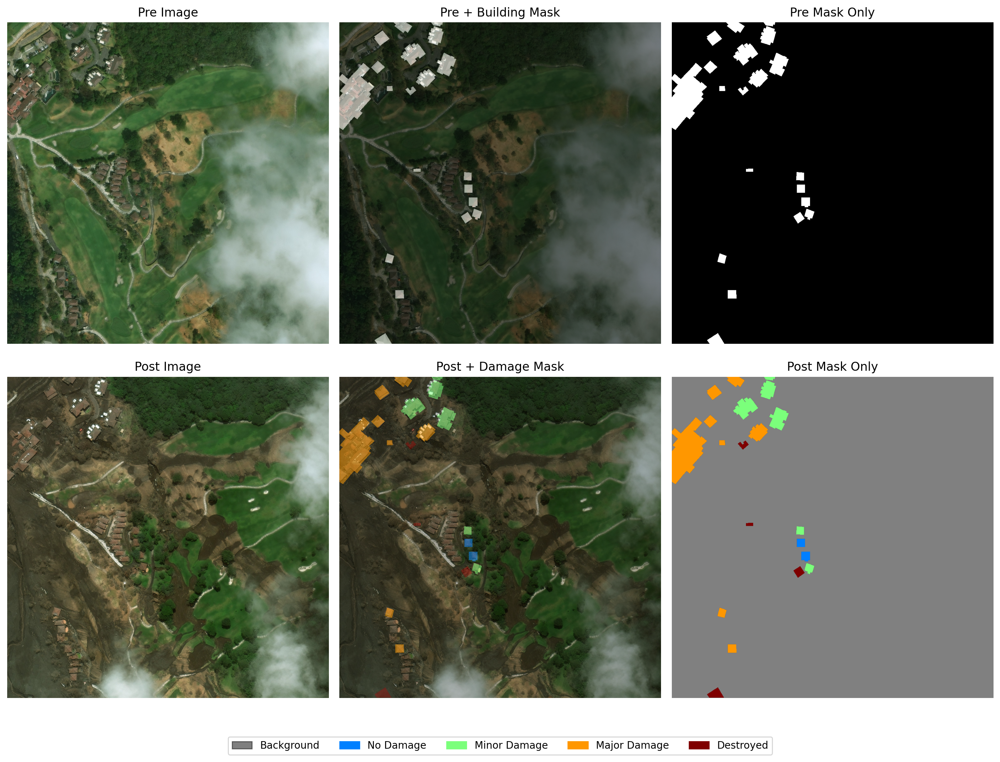

In [8]:
def get_custom_cmap():
    cmap = plt.get_cmap("jet", 5)
    colors = cmap(np.arange(5))
    colors[0] = [0, 0, 0, 0.5]  # RGBA
    return mcolors.ListedColormap(colors)

def visualize_full(sample):
    img = sample["image"]
    pre_mask = sample["pre_mask"].numpy()
    post_mask = sample["post_mask"].numpy()

    pre = img[:3].permute(1,2,0).numpy()
    post = img[3:].permute(1,2,0).numpy()

    cmap = get_custom_cmap()

    fig, axes = plt.subplots(2, 3, figsize=(14, 11), dpi=200)

    # --- PRE ---
    axes[0,0].imshow(pre)
    axes[0,0].set_title("Pre Image")
    axes[0,0].axis("off")

    axes[0,1].imshow(pre)
    axes[0,1].imshow(pre_mask, cmap="gray", alpha=0.5)
    axes[0,1].set_title("Pre + Building Mask")
    axes[0,1].axis("off")

    axes[0,2].imshow(pre_mask, cmap="gray")
    axes[0,2].set_title("Pre Mask Only")
    axes[0,2].axis("off")

    # --- POST ---
    axes[1,0].imshow(post)
    axes[1,0].set_title("Post Image")
    axes[1,0].axis("off")

    axes[1,1].imshow(post)
    axes[1,1].imshow(post_mask, cmap=cmap, alpha=0.5, vmin=0, vmax=4)
    axes[1,1].set_title("Post + Damage Mask")
    axes[1,1].axis("off")

    axes[1,2].imshow(post_mask, cmap=cmap, vmin=0, vmax=4)
    axes[1,2].set_title("Post Mask Only")
    axes[1,2].axis("off")

    # # --- COMPARISON ---
    # axes[2,0].imshow(pre_mask, cmap="gray")
    # axes[2,0].set_title("Buildings")
    # axes[2,0].axis("off")

    # axes[2,1].imshow(post_mask, cmap=cmap, vmin=0, vmax=4)
    # axes[2,1].set_title("Damage Classes")
    # axes[2,1].axis("off")

    # axes[2,2].imshow(pre)
    # axes[2,2].imshow(post_mask, cmap=cmap, alpha=0.5)
    # axes[2,2].set_title("Damage Overlay")
    # axes[2,2].axis("off")

    # --- LEGEND ---
    class_names = [
        "Background",
        "No Damage",
        "Minor Damage",
        "Major Damage",
        "Destroyed"
    ]

    colors = [cmap(i) for i in range(5)]
    patches = [mpatches.Patch(color=colors[i], label=class_names[i]) for i in range(5)]

    fig.legend(
        handles=patches,
        loc="lower center",
        ncol=5,
        bbox_to_anchor=(0.5, 0.02)
    )

    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.show()

def visualize_aug(sample, transform):
    pre = sample["image"][:3].permute(1,2,0).numpy()
    post = sample["image"][3:].permute(1,2,0).numpy()

    pre_mask = sample["pre_mask"].numpy()
    post_mask = sample["post_mask"].numpy()

    aug = transform(
        image=pre,
        image_post=post,
        pre_mask=pre_mask,
        post_mask=post_mask
    )

    aug_image = np.concatenate([aug["image"], aug["image_post"]], axis=2)

    visualize_full({
        "image": torch.tensor(aug_image).permute(2,0,1),
        "pre_mask": torch.tensor(aug["pre_mask"]),
        "post_mask": torch.tensor(aug["post_mask"])
    })

sample = dataset[0]
visualize_full(sample)

### DataLoader

/home/kyn5du/.local/lib/python3.11/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_986623/1600397621.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("jet", 5)


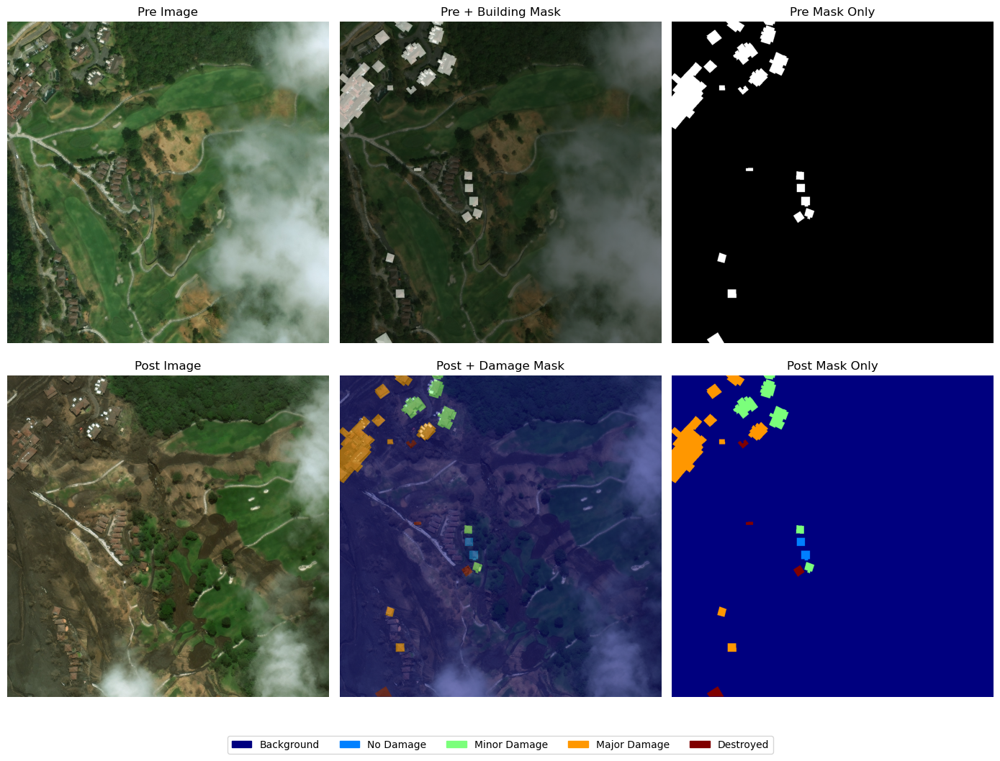

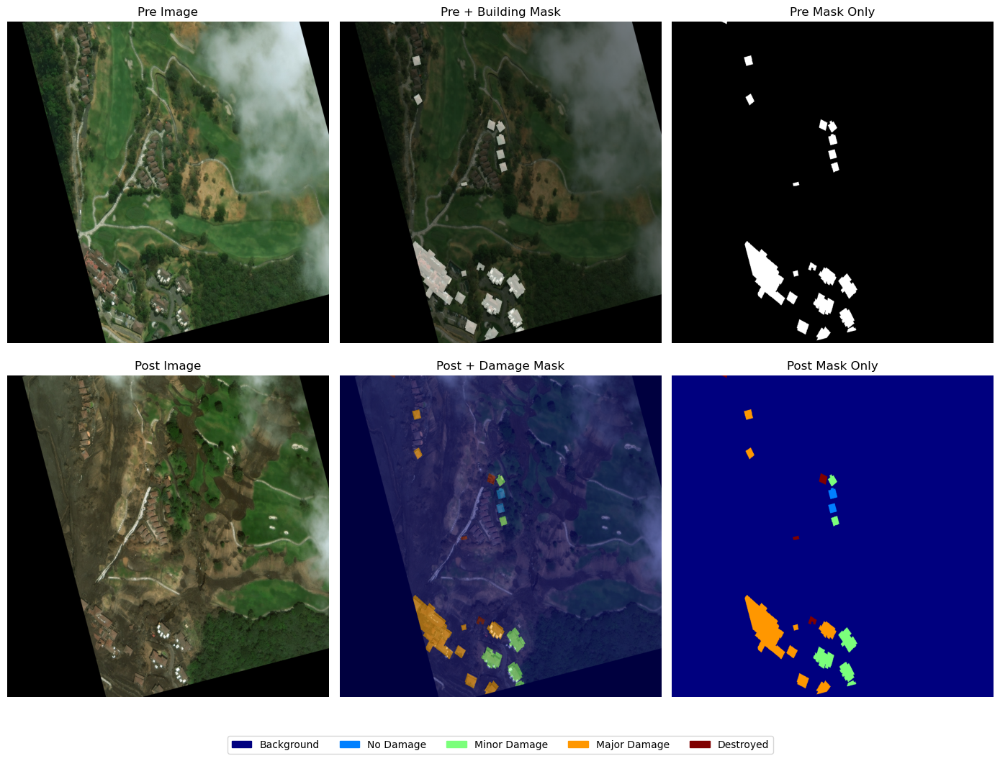

In [ ]:
train_transform = A.Compose([
    # --- Spatial (must apply to masks too) ---
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(
        shift_limit=0.1,
        scale_limit=0.2,
        rotate_limit=15,
        border_mode=0,
        p=0.2
    ),
    A.MotionBlur(p=0.1),

    # --- Color (ONLY affects image) ---
    A.RandomBrightnessContrast(p=0.2),
    A.HueSaturationValue(p=0.2),
    A.GaussNoise(p=0.2)

], additional_targets={
    "image_post": "image",
    "pre_mask": "mask",
    "post_mask": "mask"
})

# show transformations
visualize_full(sample)
visualize_aug(sample, train_transform)


In [9]:
base_folder = "content/data/xview2_jpeg"

train_dataset = XView2Dataset(base_folder+"/tier1/images_jpeg", base_folder+"/tier1/labels", transform=None)
test_dataset   = XView2Dataset(base_folder+"/test/images_jpeg", base_folder+"/test/labels")

# split train into train and validation
size_all = len(train_dataset)
print(f'Before splitting the full dataset into train and validation: len(dataset_all)={size_all}')
size_val = int(size_all * TEST_RATIO)
size_train = size_all - size_val
train_dataset, val_dataset = random_split(train_dataset, [size_train, size_val], generator=Generator().manual_seed(SEED))
print(f'After splitting the full dataset into train and val: len(dataset_train)={len(train_dataset)}. len(dataset_val)={len(val_dataset)}')


train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=1, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=1, pin_memory=True)

Before splitting the full dataset into train and validation: len(dataset_all)=2799
After splitting the full dataset into train and val: len(dataset_train)=2240. len(dataset_val)=559


/home/kyn5du/.local/lib/python3.11/site-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


### Unet Dual-Head Model

Including dual head output: essentially it the model has 2 focuses of both just predicting building location as well as prediction building damage levels. the UNet structure has a single input of the pre and post images concatenated together. I know in our proposal we talked about a Siamese network, but this may be a simpler way to start and something we can compare to more complicated models later.



In [10]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class UNetDualHead(nn.Module):
    def __init__(self, in_channels=6):
        super().__init__()

        # Layer feature sizes
        f1 = 32
        f2 = 64
        f3 = 128
        f4 = 256
        f5 = 512

        # Encoder
        self.enc1 = DoubleConv(in_channels, f1)
        self.enc2 = DoubleConv(f1, f2)
        self.enc3 = DoubleConv(f2, f3)
        self.enc4 = DoubleConv(f3, f4)

        # Pooling
        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(f4, f5)

        # Decoder
        self.up4 = nn.ConvTranspose2d(f5, f4, 2, stride=2)
        self.dec4 = DoubleConv(f5, f4)

        self.up3 = nn.ConvTranspose2d(f4, f3, 2, stride=2)
        self.dec3 = DoubleConv(f4, f3)

        self.up2 = nn.ConvTranspose2d(f3, f2, 2, stride=2)
        self.dec2 = DoubleConv(f3, f2)

        self.up1 = nn.ConvTranspose2d(f2, f1, 2, stride=2)
        self.dec1 = DoubleConv(f2, f1)

        # final shared features
        self.final_features = nn.Conv2d(f1, f1, kernel_size=1)

        # TWO HEADS
        self.building_head = nn.Conv2d(f1, 1, kernel_size=1)
        self.damage_head = nn.Conv2d(f1, 5, kernel_size=1)

    def forward(self, x):
        # encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # bottleneck
        b = self.bottleneck(self.pool(e4))

        # decoder
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        features = self.final_features(d1)

        building_out = self.building_head(features)
        damage_out = self.damage_head(features)

        return building_out, damage_out
    
    def _get_param_lists(self):
        backbone_params = []
        building_head_params = []
        damage_head_params = []

        for name, param in self.named_parameters():
            if 'building_head' in name:
                building_head_params.append(param)
            elif 'damage_head' in name:
                damage_head_params.append(param)
            else:
                backbone_params.append(param)
        
        return backbone_params, building_head_params, damage_head_params


# Loss Computation
bce = nn.BCEWithLogitsLoss()
ce  = nn.CrossEntropyLoss(reduction='none')
def masked_ce(pred, target, full_mask):
    mask = (full_mask > 0)

    m_ce = ce(pred, target)
    m_ce = (m_ce * mask).sum() / (mask.sum() + 1e-6)
    return m_ce

def iou_loss(pred, target, smooth=1e-6):
    pred = torch.sigmoid(pred)

    # get intersection and union
    intersection = (pred * target).sum(dim=(1,2,3))
    union = (pred + target - pred * target).sum(dim=(1,2,3))

    # compute and return Dice
    iou = (intersection + smooth) / (union + smooth)
    return 1 - iou.mean()

def dice_loss(pred, target, smooth=1e-6):
    pred = torch.sigmoid(pred)

    # get intersection and union
    intersection = (pred * target).sum(dim=(1,2,3))
    union = pred.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3))

    # compute and return Dice
    dice = (2 * intersection + smooth) / (union + smooth)
    return 1 - dice.mean()


def compute_dual_loss(building_out, damage_out, pre_mask, post_mask):
    pre_mask_unsq = pre_mask.unsqueeze(1).float()
    
    # building loss
    # loss_b = bce(building_out, pre_mask_unsq)
    # loss_b = iou_loss(building_out, pre_mask_unsq)
    # loss_b = dice_loss(building_out, pre_mask_unsq)
    loss_b = bce(building_out, pre_mask_unsq) + dice_loss(building_out, pre_mask_unsq)

    # damage loss (only on buildings)
    loss_d = masked_ce(damage_out, post_mask, pre_mask)

    return loss_b + loss_d, loss_b, loss_d

### UNet Training

In [ ]:
device_name = "cuda" if torch.cuda.is_available() else "cpu"
device = torch.device(device_name)
scaler = torch.amp.GradScaler('cuda')
model = UNetDualHead(in_channels=6).to(device_name)
bb_params, bh_params, dh_params = model._get_param_lists()
optimizer = torch.optim.Adam([
    {'params': bb_params, 'lr': 1e-4},
    {'params': bh_params, 'lr': 1e-4},
    {'params': dh_params, 'lr': 1e-4},  # slower for stability
])

def train_one_epoch(loader):
    model.train()

    total_loss = 0
    total_building_loss = 0
    total_damage_loss = 0
    total_samples = 0

    for batch in tqdm(loader, disable=PREVENT_TQDM):
        # Move data from the CPU to the GPU
        images = batch["image"].to(device, non_blocking=True)
        pre_mask = batch["pre_mask"].to(device, non_blocking=True)
        post_mask = batch["post_mask"].to(device, non_blocking=True)

        # forward pass
        with torch.amp.autocast(device_type="cuda"):
            building_out, damage_out = model(images)
            loss, l_building, l_damage = compute_dual_loss(building_out, damage_out, pre_mask, post_mask)

        # backpropogation
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_building_loss += l_building.item() * batch_size
        total_damage_loss += l_damage.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples, total_building_loss / total_samples, total_damage_loss / total_samples

@torch.no_grad()
def validate(loader):
    model.eval()

    total_loss = 0
    total_building_loss = 0
    total_damage_loss = 0
    total_samples = 0

    for batch in tqdm(loader, disable=PREVENT_TQDM):
        # Move data from the CPU to the GPU
        images = batch["image"].to(device, non_blocking=True)
        pre_mask = batch["pre_mask"].to(device, non_blocking=True)
        post_mask = batch["post_mask"].to(device, non_blocking=True)

        # get validation loss
        with torch.amp.autocast(device_type="cuda"):
            building_out, damage_out = model(images)
            loss, l_building, l_damage = compute_dual_loss(building_out, damage_out, pre_mask, post_mask)

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_building_loss += l_building.item() * batch_size
        total_damage_loss += l_damage.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples, total_building_loss / total_samples, total_damage_loss / total_samples

In [12]:
# graphing functions

# Total Loss Plot
def plot_loss(training_losses, validation_losses, sub_title, file_subname, save=True, show=True):
    plt.figure(figsize=(8,5))
    plt.plot(training_losses, label="Train Loss")
    plt.plot(validation_losses, label="Validation Loss")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{sub_title} vs Validation Loss")
    plt.legend()
    plt.grid(True)

    if save:
        plt.savefig(f"img_output/{TIMESTAMP}--{file_subname}.png", dpi=300, bbox_inches="tight")
    if show:
        plt.show()
    plt.close()

In [ ]:
epochs = 240

train_losses = []
train_b_losses = []
train_d_losses = []
val_losses = []
val_b_losses = []
val_d_losses = []
epochs_without_improvement = 0
best_model_state = None

i = 1
for epoch in range(epochs):
    print(f"Epoch {epoch+1}")
    train_loss, train_b_loss, train_d_loss = train_one_epoch(train_loader)
    val_loss, val_b_loss, val_d_loss = validate(val_loader)

    # save if best
    if val_loss < min(val_losses, default=9999):
        best_model_state = model.state_dict()
        torch.save(model.state_dict(), f'sbatch_output/model_weights--{TIMESTAMP}.pth')
        epochs_without_improvement = 0

    train_losses.append(train_loss)
    train_b_losses.append(train_b_loss)
    train_d_losses.append(train_d_loss)
    val_losses.append(val_loss)
    val_b_losses.append(val_b_loss)
    val_d_losses.append(val_d_loss)

    if i%PRINT_EPOCH == 0 or i==1:
        print(f"Train Loss: {train_loss:.8f}")
        print(f"    Building: {train_b_loss:.8f}")
        print(f"    Damage: {train_d_loss:.8f}")
        print(f"Val Loss:   {val_loss:.8f}")
        print(f"    Building: {val_b_loss:.8f}")
        print(f"    Damage: {val_d_loss:.8f}")
        print()

        plot_loss(train_losses, val_losses, "Total Training", "total_loss", show=False)
        plot_loss(train_b_losses, val_b_losses, "Building Training", "building_loss", show=False)
        plot_loss(train_d_losses, val_d_losses, "Damage Training", "damage_loss", show=False)

    if epochs_without_improvement == 10:
        print("LOWERING LEARNING-RATE")
        for param_group in optimizer.param_groups:
            param_group['lr'] /= 5
        if best_model_state is not None:
            model.load_state_dict(best_model_state)
        
    if epochs_without_improvement == 20:
        print("EARLY STOPPING TRIGGERED")
        break

    i += 1
    epochs_without_improvement += 1

# Total Loss Plot
plot_loss(train_losses, val_losses, "Total Training", "total_loss")

# Building Loss Plot
plot_loss(train_b_losses, val_b_losses, "Building Training", "building_loss")

# Damage Loss Plot
plot_loss(train_d_losses, val_d_losses, "Damage Training", "damage_loss")

Epoch 1


  0%|          | 0/234 [00:00<?, ?it/s]/home/kyn5du/.local/lib/python3.11/site-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 6 worker processes in total. Our suggested max number of worker in current system is 1, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
 15%|█▍        | 35/234 [01:18<07:27,  2.25s/it] 


KeyboardInterrupt: 